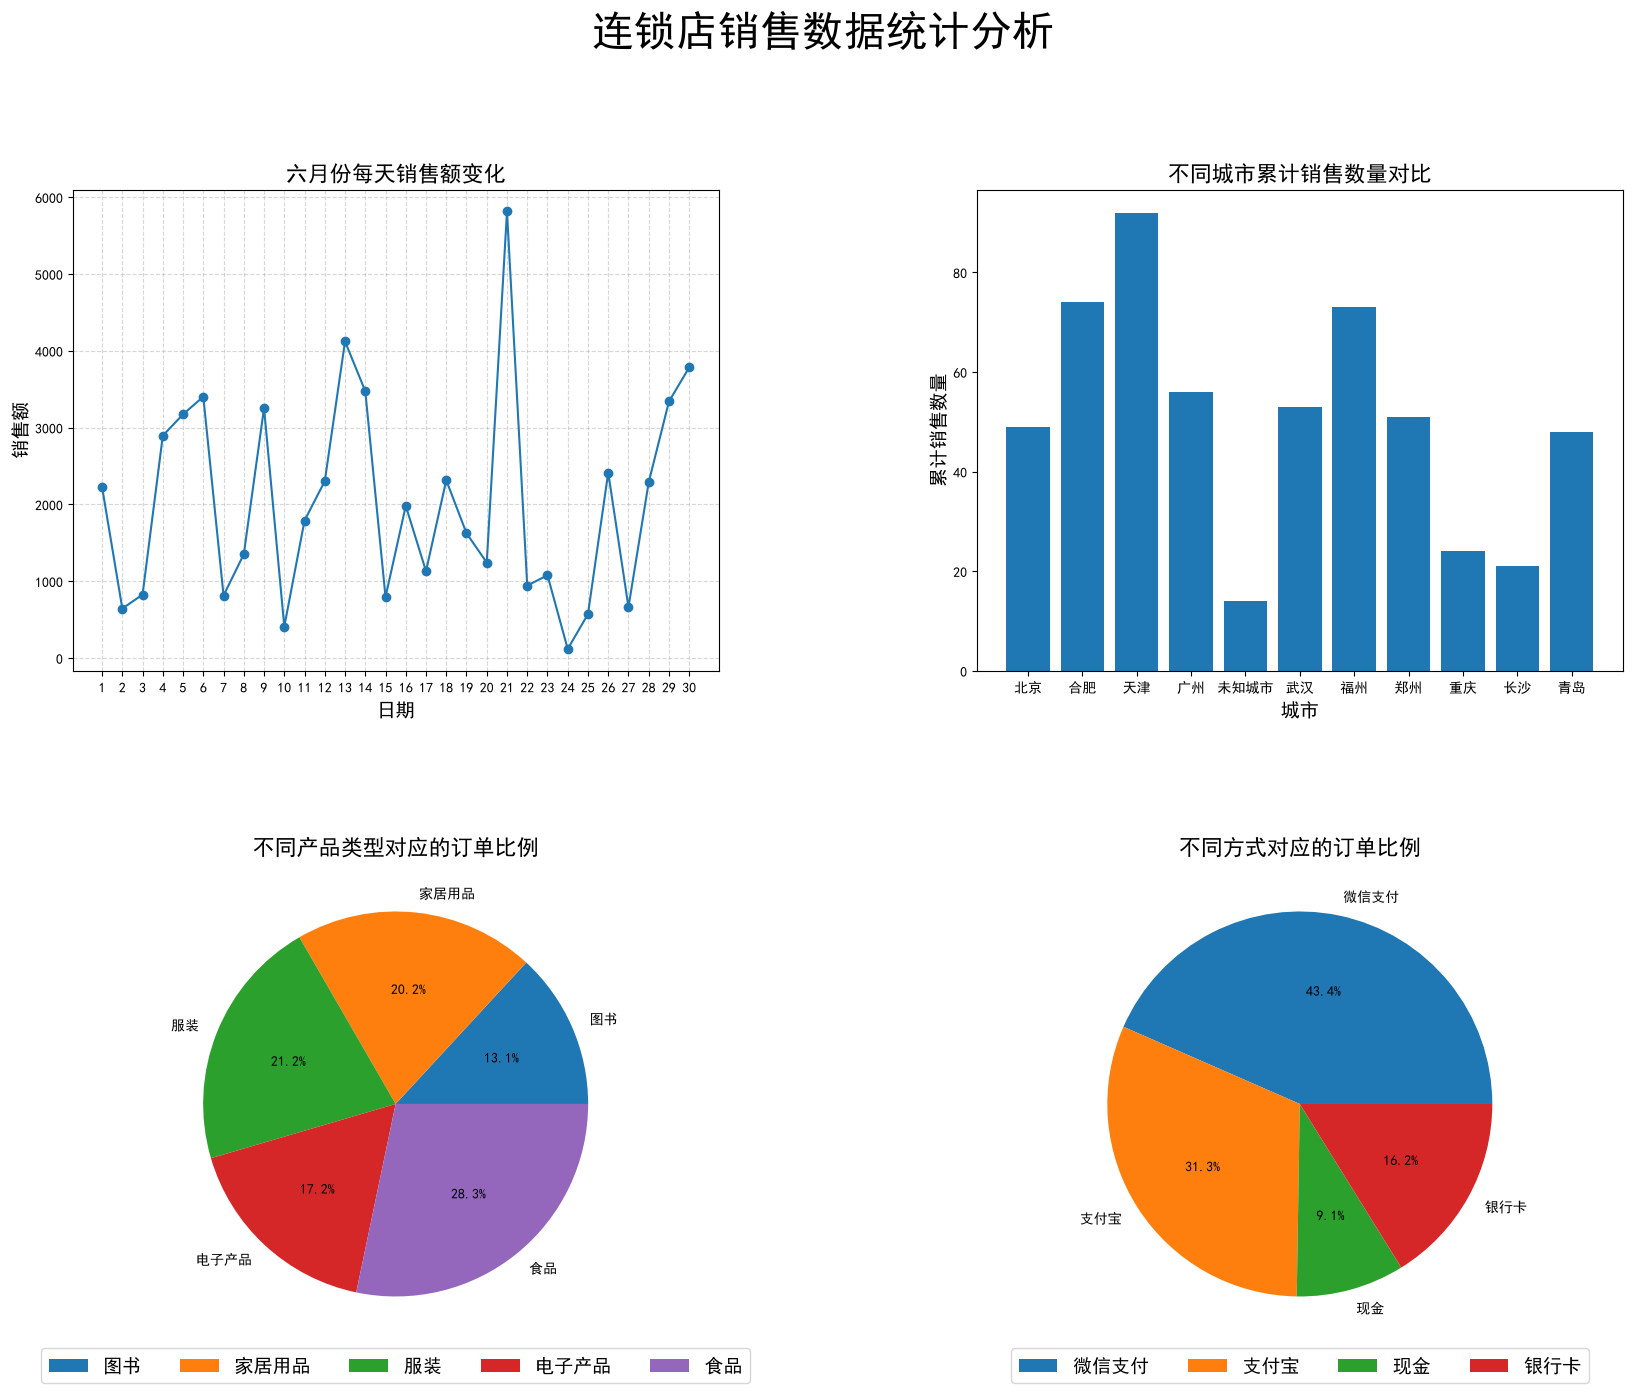

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import lineStyles
from matplotlib.pyplot import figure, subplot, subplots_adjust
from matplotlib.axes import Axes as Axes
#用黑色字体来显示中文
plt.rcParams['font.sans-serif'] = ['SimHei']
#设置图表大小,把画布分为2行2列，figure是指整个画布，ax是画布上的子图，dpi是分辨率
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(20, 15),dpi=100)
#设置图表的大标题，fontsize是字体大小,x是标题的x坐标，y是标题的y坐标，ha是水平对齐方式
fig.suptitle('连锁店销售数据统计分析',fontsize=30,x=0.5,y=1,ha='center')

#subplots_adjust是调整子图之间的间距
fig, subplots_adjust(wspace=0.4, hspace=0.4)
#获取每个子图的 Axes 对象
axes1:Axes = ax[0, 0]
axes2:Axes = ax[0, 1]
axes3:Axes = ax[1, 0]
axes4:Axes = ax[1, 1]
#读取store_sales数据
data = pd.read_csv('data/store_sales.csv')
#需求一：统计每天销售额的变化（折线统计图）
data['订单日期'] = data['订单日期'].str.replace('/', '-')
data=data[
    (data['销售数量']>=0)&(data['单价']>=0)
]
data['销售额'] = data['销售数量'] * data['单价']
#先按照订单日期进行分组，然后计算每天的销售额总和
date_count=data.groupby('订单日期')['销售额'].sum()
#x轴数据 获取日期，截取六月的每日日期为x轴数据
date_x = list(range(1, 31, 1))
axes1.set_xticks(date_x)
#y轴数据 获取销售额
date_y = date_count.values.tolist()

#绘制折线图
axes1.plot(date_x, date_y, marker='o')
axes1.set_xlabel('日期', fontsize=14)
axes1.set_ylabel('销售额', fontsize=14)
axes1.set_title('六月份每天销售额变化', fontsize=16)
axes1.grid(linestyle='--',alpha=0.5)

#需求二：统计对比不同城市的累计销售数量，（柱状图）
# 填充缺失值
data['客户所在城市'] = data['客户所在城市'].fillna('未知城市')
# 计算累计销售数量
city_count = data.groupby('客户所在城市')['销售数量'].sum()
axes2.bar(city_count.index, city_count.values)
axes2.set_xlabel('城市', fontsize=14)
axes2.set_ylabel('累计销售数量', fontsize=14)
axes2.set_title('不同城市累计销售数量对比', fontsize=16)
#需求三：统计不同产品类型对应的订单比例（饼状图）
category_count = data.groupby('产品类别')['订单号'].count()
axes3.pie(category_count.values, labels=category_count.index, autopct='%1.1f%%')

axes3.set_title('不同产品类型对应的订单比例', fontsize=16)
axes3.legend(fontsize=14, ncol=5,loc='lower center' ,bbox_to_anchor=(0.5, -0.1))
#需求四：统计不同方式对应的订单比例（饼状图）
payment_count = data.groupby('支付方式')['订单号'].count()

axes4.pie(payment_count.values, labels=payment_count.index, autopct='%1.1f%%')
axes4.set_title('不同方式对应的订单比例', fontsize=16)
axes4.legend(fontsize=14, ncol=4,loc='lower center',bbox_to_anchor=(0.5, -0.1))

#最后把制作的图进行保存
plt.savefig('data/sales_analysis.png', dpi=100, bbox_inches='tight' )
